<a href="https://colab.research.google.com/github/feyzatesoglu/all-aml-gene-expression-classification/blob/main/notebooks/02_external_dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import csv
import gzip
import json
import platform
import subprocess
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import ttest_ind, false_discovery_control
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SEED = 42
ACCESSION = "GSE13159"
MATRIX_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE13nnn/GSE13159/matrix/GSE13159_series_matrix.txt.gz"
)

# Gerekirse proje kökünü burada değiştirin.
colab_repo = Path("/content/all-aml-gene-expression-classification")
PROJECT_ROOT = colab_repo if colab_repo.exists() else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Önceki Colab indirmesini yeniden kullan.
DATA_DIR = (Path("/content/all_aml_external_data")
            if Path("/content").exists()
            else PROJECT_ROOT / "data" / "external" / ACCESSION)
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for directory in [DATA_DIR, FIGURE_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = DATA_DIR / f"{ACCESSION}_series_matrix.txt.gz"
CLASS_PALETTE = {"ALL": "steelblue", "AML": "darkorange"}
TYPE_PALETTE = {"bone marrow": "teal", "peripheral blood": "goldenrod"}
plt.rcParams["svg.fonttype"] = "none"

versions = {package: version(package) for package in
            ["numpy", "pandas", "scipy", "matplotlib", "seaborn", "scikit-learn"]}
versions["python"] = platform.python_version()
print("Proje kökü:", PROJECT_ROOT)
print("Veri klasörü:", DATA_DIR)
print(versions)


Proje kökü: /content
Veri klasörü: /content/all_aml_external_data
{'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'scikit-learn': '1.6.1', 'python': '3.13.18'}


In [ ]:
def download_matrix(url, destination):
    if not destination.exists():
        staging = destination.parent / "downloads"
        staging.mkdir(exist_ok=True)
        partial = staging / destination.name
        previous_partial = destination.with_suffix(".part")
        if previous_partial.exists() and not partial.exists():
            previous_partial.replace(partial)
        print("Dosya indiriliyor / indirmeye devam ediliyor...", flush=True)
        subprocess.run([
            "wget", "--continue", "--tries=10", "--timeout=60",
            "--waitretry=5", "--retry-connrefused",
            "--retry-on-http-error=429,500,502,503,504",
            "--progress=dot:giga", "--directory-prefix", str(staging), url
        ], check=True)
        subprocess.run(["gzip", "-t", str(partial)], check=True)
        partial.replace(destination)
    else:
        subprocess.run(["gzip", "-t", str(destination)], check=True)
    print(f"Dosya hazır: {destination.stat().st_size / 1024**2:.1f} MiB")

download_matrix(MATRIX_URL, MATRIX_PATH)


Dosya hazır: 845.5 MiB


In [ ]:
def read_metadata(path):
    rows = {}
    table_start = None
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line_number, line in enumerate(stream):
            if line.startswith("!series_matrix_table_begin"):
                table_start = line_number + 1
                break
            if line.startswith("!Sample_"):
                fields = next(csv.reader([line], delimiter="\t"))
                key = fields[0].removeprefix("!Sample_")
                rows.setdefault(key, []).append(fields[1:])
    if table_start is None:
        raise ValueError("Ekspresyon tablosu bulunamadı.")
    sample_ids = rows["geo_accession"][0]
    frame = pd.DataFrame(index=pd.Index(sample_ids, name="sample_id"))
    for key, entries in rows.items():
        for number, values in enumerate(entries, 1):
            assert len(values) == len(sample_ids), key
            column = key if len(entries) == 1 else f"{key}_{number}"
            frame[column] = values
    assert frame.index.is_unique
    return frame, table_start

metadata, table_start = read_metadata(MATRIX_PATH)
assert len(metadata) == 2096
metadata["original_class"] = metadata["characteristics_ch1_2"].str.replace(
    r"^leukemia class:\s*", "", regex=True).str.strip()
metadata["sample_type"] = metadata["characteristics_ch1_1"].str.replace(
    r"^sample type:\s*", "", regex=True).str.strip()

ALL_SUBTYPES = [
    "mature B-ALL with t(8;14)", "c-ALL/Pre-B-ALL without t(9;22)",
    "T-ALL", "c-ALL/Pre-B-ALL with t(9;22)",
    "Pro-B-ALL with t(11q23)/MLL", "ALL with t(12;21)",
    "ALL with hyperdiploid karyotype", "ALL with t(1;19)"
]
AML_SUBTYPES = [
    "AML with normal karyotype + other abnormalities",
    "AML complex aberrant karyotype", "AML with t(8;21)",
    "AML with t(11q23)/MLL", "AML with t(15;17)",
    "AML with inv(16)/t(16;16)"
]
EXCLUDED_CLASSES = {"CLL", "MDS", "CML", "Non-leukemia and healthy bone marrow"}
mapping = {**dict.fromkeys(ALL_SUBTYPES, "ALL"),
           **dict.fromkeys(AML_SUBTYPES, "AML")}
unknown = set(metadata["original_class"]) - set(mapping) - EXCLUDED_CLASSES
assert not unknown, f"Beklenmeyen etiketler: {unknown}"
metadata["class"] = metadata["original_class"].map(mapping)
selected_metadata = metadata.loc[metadata["class"].notna()].copy()
selected_metadata["target"] = selected_metadata["class"].map({"ALL": 0, "AML": 1})
assert selected_metadata["class"].value_counts().to_dict() == {"ALL": 750, "AML": 542}
assert selected_metadata["platform_id"].eq("GPL570").all()
assert selected_metadata["sample_type"].isin(TYPE_PALETTE).all()

class_counts = selected_metadata["class"].value_counts().reindex(CLASS_PALETTE)
sample_type_counts = pd.crosstab(
    selected_metadata["class"], selected_metadata["sample_type"], margins=True)
display(class_counts.to_frame("sample_count"))
display(sample_type_counts)
for description in selected_metadata["data_processing"].dropna().unique():
    print(description)


,sample_count
class,
ALL,750
AML,542


sample_type,bone marrow,peripheral blood,All
class,,,
ALL,710,40,750
AML,501,41,542
All,1211,81,1292


Data pre-processing included a summarization and quantile normalization step to generate probe set level signal intensities for each microarray experiment and was performed as previously published by Liu WM et al. PQN and DQN: algorithms for expression microarrays. J.Theor.Biol. 2006;243:273-278.


In [ ]:
sample_ids = selected_metadata.index.tolist()
expression = pd.read_csv(
    MATRIX_PATH, compression="gzip", sep="\t", skiprows=table_start,
    comment="!", usecols=["ID_REF"] + sample_ids,
    dtype={"ID_REF": "string", **dict.fromkeys(sample_ids, "float32")}
).set_index("ID_REF")
assert expression.index.is_unique
X_external = expression.loc[:, sample_ids].T.copy()
X_external.index.name = "sample_id"
X_external.columns.name = "probe_id"
y_external = selected_metadata.loc[X_external.index, "target"].copy()
del expression
assert X_external.shape == (1292, 54675)
assert X_external.index.equals(y_external.index)

missing_per_probe = X_external.isna().sum()
missing_per_sample = X_external.isna().sum(axis=1)
all_missing_probes = missing_per_probe.index[missing_per_probe == len(X_external)]
X_external_clean = X_external.drop(columns=all_missing_probes).copy()
values = X_external_clean.to_numpy(copy=False)
assert np.isfinite(values).all(), "Kalan eksik/sonsuz değerleri inceleyin."
assert values.min() >= 0 and values.max() <= 1, "Beklenmeyen veri ölçeği."

quality = pd.Series({
    "samples": len(X_external), "original_probes": X_external.shape[1],
    "original_missing_values": int(missing_per_probe.sum()),
    "all_missing_probes_removed": len(all_missing_probes),
    "remaining_probes": X_external_clean.shape[1],
    "remaining_missing_values": int(np.isnan(values).sum()),
    "negative_values": int((values < 0).sum()),
    "zero_values": int((values == 0).sum())
}, name="value")
quantiles = pd.Series(
    np.quantile(values, [0, .01, .25, .5, .75, .99, 1]),
    index=["minimum", "q01", "q25", "median", "q75", "q99", "maximum"],
    name="expression"
)
display(quality.to_frame())
display(quantiles.to_frame())
display(X_external_clean.iloc[:5, :5])


,value
samples,1292
original_probes,54675
original_missing_values,58140
all_missing_probes_removed,45
remaining_probes,54630
remaining_missing_values,0
negative_values,0
zero_values,225845


,expression
minimum,0.000000
q01,0.007585
q25,0.123870
median,0.249634
q75,0.415304
q99,0.805776
maximum,1.000000


probe_id,1007_s_at,1053_at,117_at,121_at,1255_g_at
sample_id,,,,,
GSM329407,0.361346,0.450274,0.431178,0.405517,0.160812
GSM329408,0.396426,0.559457,0.402577,0.437968,0.089130
GSM329409,0.419317,0.436466,0.306609,0.479352,0.117863
GSM329410,0.424651,0.512677,0.217119,0.484471,0.222672
GSM329411,0.287776,0.194097,0.355157,0.453368,0.180248


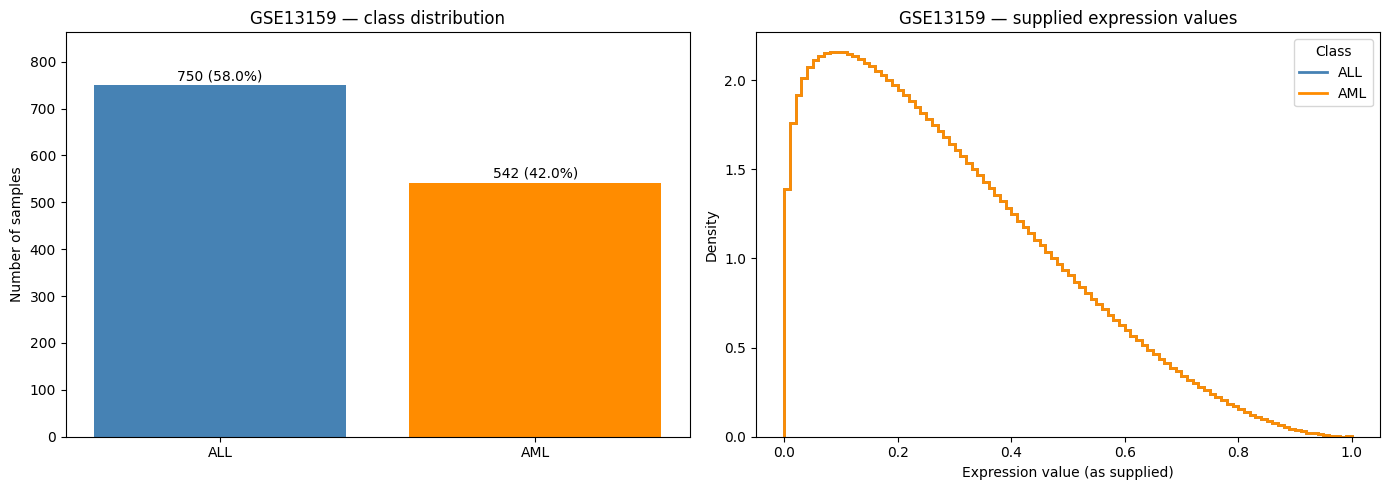

In [ ]:
def save_figure(figure, name):
    figure.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    figure.savefig(FIGURE_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(class_counts.index, class_counts.values,
                   color=list(CLASS_PALETTE.values()))
for bar, count in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, count + 10,
                 f"{count} ({100*count/class_counts.sum():.1f}%)", ha="center")
axes[0].set(title="GSE13159 — class distribution", ylabel="Number of samples",
            ylim=(0, class_counts.max()*1.15))
bins = np.linspace(0, 1, 101)
labels = y_external.to_numpy()
for label, name in [(0, "ALL"), (1, "AML")]:
    histogram = np.zeros(100, dtype=np.int64)
    for row in np.flatnonzero(labels == label):
        histogram += np.histogram(values[row], bins=bins)[0]
    density = histogram / (histogram.sum() * np.diff(bins))
    axes[1].stairs(density, bins, label=name, color=CLASS_PALETTE[name], linewidth=2)
axes[1].set(title="GSE13159 — supplied expression values",
            xlabel="Expression value (as supplied)", ylabel="Density")
axes[1].legend(title="Class")
fig.tight_layout()
save_figure(fig, "gse13159_distributions")
plt.show()


sample_count  median_of_sample_medians  \
class sample_type                                                
ALL   bone marrow                710                  0.249634   
      peripheral blood            40                  0.249634   
AML   bone marrow                501                  0.249634   
      peripheral blood            41                  0.249634   

                        median_of_sample_IQRs  
class sample_type                              
ALL   bone marrow                    0.291428  
      peripheral blood               0.291428  
AML   bone marrow                    0.291428  
      peripheral blood               0.291428

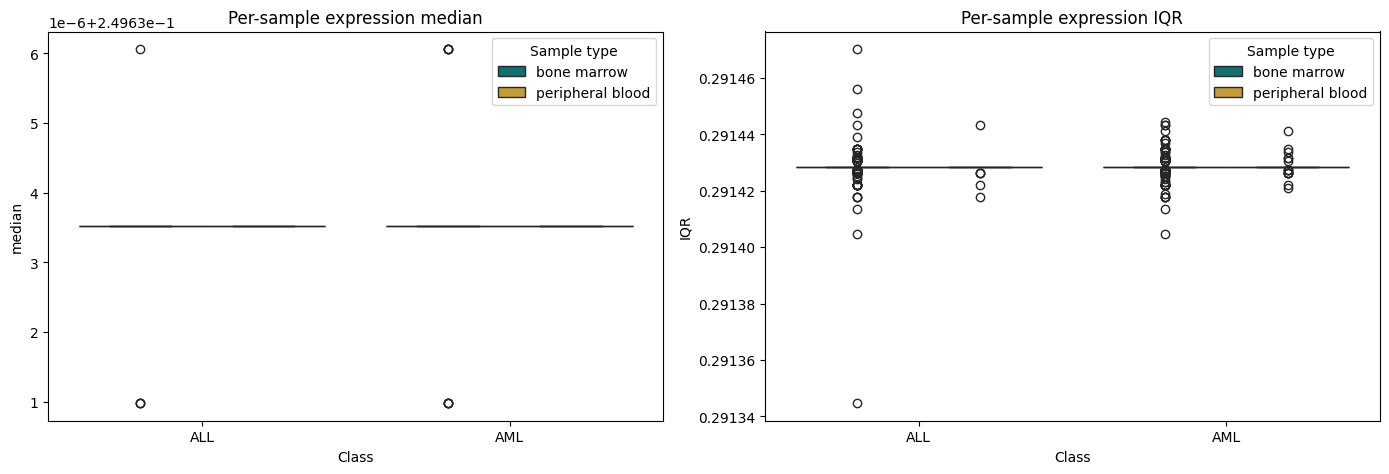

,class,sample_type,median,IQR
sample_id,,,,
GSM330129,ALL,bone marrow,0.249634,0.291470
GSM329830,ALL,bone marrow,0.249634,0.291456
GSM330147,ALL,bone marrow,0.249631,0.291448
GSM330477,AML,bone marrow,0.249634,0.291444
GSM330911,AML,bone marrow,0.249634,0.291443
GSM330457,AML,bone marrow,0.249634,0.291443
GSM329417,ALL,peripheral blood,0.249634,0.291443
GSM330006,ALL,bone marrow,0.249634,0.291443
GSM330832,AML,peripheral blood,0.249634,0.291441


In [ ]:
sample_summary = selected_metadata.loc[
    X_external_clean.index, ["class", "sample_type"]].copy()
quartiles = X_external_clean.quantile([.25, .5, .75], axis=1).T
sample_summary["median"] = quartiles[.5]
sample_summary["IQR"] = quartiles[.75] - quartiles[.25]
display(sample_summary.groupby(["class", "sample_type"]).agg(
    sample_count=("median", "size"),
    median_of_sample_medians=("median", "median"),
    median_of_sample_IQRs=("IQR", "median")
))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["median", "IQR"]):
    sns.boxplot(data=sample_summary, x="class", y=metric, hue="sample_type",
                order=list(CLASS_PALETTE), hue_order=list(TYPE_PALETTE),
                palette=TYPE_PALETTE, ax=ax)
    ax.set(title=f"Per-sample expression {metric}", xlabel="Class")
    ax.legend(title="Sample type")
fig.tight_layout()
save_figure(fig, "gse13159_sample_summary")
plt.show()
display(sample_summary.sort_values("IQR", ascending=False).head(10))


PCA prob sayısı: 54630
Sabit prob sayısı: 0
PC1: %9.97; PC2: %6.64
Toplam: %16.61


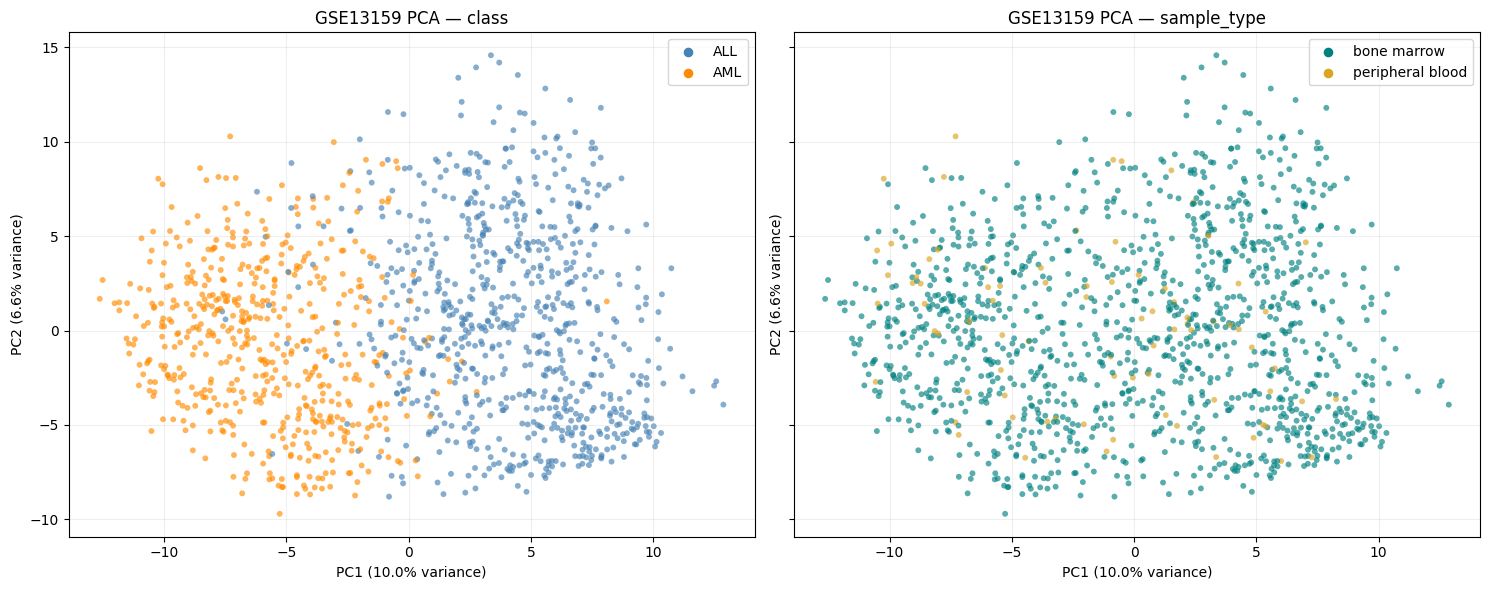

In [ ]:
variable_mask = X_external_clean.var(axis=0, ddof=0) > 0
X_external_pca = X_external_clean.loc[:, variable_mask]
print("PCA prob sayısı:", X_external_pca.shape[1])
print("Sabit prob sayısı:", int((~variable_mask).sum()))

def embedding_table(coordinates, names):
    table = selected_metadata.loc[X_external_pca.index, ["class", "sample_type"]].copy()
    table[names[0]], table[names[1]] = coordinates[:, 0], coordinates[:, 1]
    return table

def plot_embedding(table, columns, title, axis_labels, filename):
    ordered = table.sample(frac=1, random_state=SEED)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
    for ax, field, palette in zip(axes, ["class", "sample_type"],
                                  [CLASS_PALETTE, TYPE_PALETTE]):
        ax.scatter(ordered[columns[0]], ordered[columns[1]],
                   c=ordered[field].map(palette), s=18, alpha=.65, edgecolors="none")
        for label, color in palette.items():
            ax.scatter([], [], color=color, label=label, s=35)
        ax.set(title=f"GSE13159 {title} — {field}",
               xlabel=axis_labels[0], ylabel=axis_labels[1])
        ax.legend(); ax.grid(alpha=.2)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()

pca_external = PCA(n_components=2, svd_solver="randomized", random_state=SEED)
pca_coordinates = pca_external.fit_transform(X_external_pca)
pca_variance = pca_external.explained_variance_ratio_ * 100
print(f"PC1: %{pca_variance[0]:.2f}; PC2: %{pca_variance[1]:.2f}")
print(f"Toplam: %{pca_variance.sum():.2f}")
pca_table = embedding_table(pca_coordinates, ["PC1", "PC2"])
plot_embedding(pca_table, ["PC1", "PC2"], "PCA",
               [f"PC1 ({pca_variance[0]:.1f}% variance)",
                f"PC2 ({pca_variance[1]:.1f}% variance)"], "gse13159_pca")


In [ ]:
pca_for_tsne = PCA(n_components=50, svd_solver="randomized", random_state=SEED)
X_reduced = pca_for_tsne.fit_transform(X_external_pca)
print(f"50 PCA bileşeninin açıkladığı varyans: %{100*pca_for_tsne.explained_variance_ratio_.sum():.2f}")
tsne_external = TSNE(n_components=2, perplexity=30, init="pca",
                     learning_rate="auto", max_iter=1500, random_state=SEED)
tsne_coordinates = tsne_external.fit_transform(X_reduced)
tsne_table = embedding_table(tsne_coordinates, ["TSNE1", "TSNE2"])
plot_embedding(tsne_table, ["TSNE1", "TSNE2"], "t-SNE",
               ["t-SNE 1", "t-SNE 2"], "gse13159_tsne")


50 PCA bileşeninin açıkladığı varyans: %50.69


In [ ]:
def compare_probes(matrix, target, block_size=1000):
    assert matrix.index.equals(target.index)
    all_mask, aml_mask = target.to_numpy() == 0, target.to_numpy() == 1
    parts, warning_rows = [], []
    for start in range(0, matrix.shape[1], block_size):
        block = matrix.iloc[:, start:start + block_size]
        array = block.to_numpy(dtype=np.float64)
        group_all, group_aml = array[all_mask], array[aml_mask]
        constant_all = np.ptp(group_all, axis=0) == 0
        constant_aml = np.ptp(group_aml, axis=0) == 0
        testable = ~(constant_all & constant_aml)
        p_values = np.ones(block.shape[1])
        if testable.any():
            with warnings.catch_warnings(record=True) as captured:
                warnings.simplefilter("always", RuntimeWarning)
                result = ttest_ind(group_aml[:, testable], group_all[:, testable],
                                   axis=0, equal_var=False, nan_policy="raise")
            for warning in captured:
                warning_rows.append({"block_start": start, "message": str(warning.message)})
            assert np.isfinite(result.pvalue).all(), "Sonlu olmayan p-değerini inceleyin."
            p_values[testable] = result.pvalue
        mean_all, mean_aml = group_all.mean(axis=0), group_aml.mean(axis=0)
        parts.append(pd.DataFrame({
            "mean_ALL": mean_all, "mean_AML": mean_aml,
            "difference_AML_minus_ALL": mean_aml - mean_all,
            "constant_ALL": constant_all, "constant_AML": constant_aml,
            "testable": testable, "p_value": p_values
        }, index=block.columns))
    stats = pd.concat(parts)
    stats.index.name = "probe_id"
    stats["p_adj_BH"] = false_discovery_control(stats["p_value"].to_numpy(), method="bh")
    stats["significant_BH_0.05"] = stats["testable"] & (stats["p_adj_BH"] < .05)
    stats = stats.reset_index().sort_values(
        ["p_adj_BH", "p_value", "probe_id"]).set_index("probe_id")
    return stats, pd.DataFrame(warning_rows, columns=["block_start", "message"])

external_probe_stats, statistical_warnings = compare_probes(X_external_clean, y_external)
print("Toplam prob:", len(external_probe_stats))
print("Test uygulanan:", int(external_probe_stats["testable"].sum()))
print("BH sonrası anlamlı:", int(external_probe_stats["significant_BH_0.05"].sum()))
print("Sayısal olarak sıfır p-değeri:", int(external_probe_stats["p_value"].eq(0).sum()))
print("Uyarı sayısı:", len(statistical_warnings))
if not statistical_warnings.empty:
    display(statistical_warnings)
display(external_probe_stats.head(20))


In [ ]:
top_probes = external_probe_stats.loc[
    external_probe_stats["significant_BH_0.05"]].head(30).index
assert len(top_probes) == 30
heatmap_data = X_external_clean.loc[:, top_probes].T
heatmap_z = heatmap_data.sub(heatmap_data.mean(axis=1), axis=0).div(
    heatmap_data.std(axis=1, ddof=1), axis=0)
assert np.isfinite(heatmap_z.to_numpy()).all()
plot_metadata = selected_metadata.loc[heatmap_z.columns]
column_colors = pd.DataFrame({
    "Class": plot_metadata["class"].map(CLASS_PALETTE),
    "Sample type": plot_metadata["sample_type"].map(TYPE_PALETTE)
})
g_external = sns.clustermap(
    heatmap_z, cmap="vlag", center=0, vmin=-3, vmax=3,
    method="average", metric="euclidean", col_colors=column_colors,
    figsize=(17, 11), xticklabels=False, yticklabels=True,
    cbar_kws={"label": "Expression z-score"}
)
g_external.ax_heatmap.set_xlabel(
    f"{len(selected_metadata):,} samples — ordered by hierarchical clustering")
g_external.ax_heatmap.set_ylabel("Probe ID")
g_external.ax_heatmap.tick_params(axis="y", labelsize=8)
g_external.fig.suptitle("GSE13159 — top 30 BH-ranked probes", y=1.03)
g_external.ax_col_dendrogram.legend(
    handles=[Patch(facecolor=color, label=name)
             for palette in [CLASS_PALETTE, TYPE_PALETTE]
             for name, color in palette.items()],
    loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False
)
save_figure(g_external.fig, "gse13159_top30_probe_heatmap")
plt.show()


In [ ]:
selected_metadata[["original_class", "class", "target", "sample_type", "platform_id"]].to_csv(
    TABLE_DIR / "gse13159_selected_metadata.csv")
quality.to_csv(TABLE_DIR / "gse13159_quality_summary.csv")
quantiles.to_csv(TABLE_DIR / "gse13159_expression_quantiles.csv")
sample_type_counts.to_csv(TABLE_DIR / "gse13159_class_by_sample_type.csv")
pd.Series(all_missing_probes, name="probe_id").to_csv(
    TABLE_DIR / "gse13159_removed_probes.csv", index=False)
sample_summary.to_csv(TABLE_DIR / "gse13159_sample_summary.csv")
pca_table.to_csv(TABLE_DIR / "gse13159_pca_coordinates.csv")
tsne_table.to_csv(TABLE_DIR / "gse13159_tsne_coordinates.csv")
external_probe_stats.to_csv(TABLE_DIR / "gse13159_probe_statistics.csv")
external_probe_stats.loc[top_probes].to_csv(TABLE_DIR / "gse13159_heatmap_top30_probes.csv")
statistical_warnings.to_csv(TABLE_DIR / "gse13159_statistical_warnings.csv", index=False)
run_info = {
    "accession": ACCESSION, "matrix_url": MATRIX_URL, "seed": SEED,
    "versions": versions, "additional_log_transform": False,
    "pca_explained_variance_percent": pca_variance.tolist(),
    "tsne_pca_variance_percent": float(100*pca_for_tsne.explained_variance_ratio_.sum()),
    "tsne_perplexity": 30, "tsne_max_iter": 1500,
    "preprocessing_note": "Source reports summarization and quantile normalization; exact origin of 0–1 scale remains unverified."
}
(TABLE_DIR / "gse13159_run_info.json").write_text(
    json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print("Grafikler:", FIGURE_DIR)
print("Tablolar:", TABLE_DIR)


In [28]:
from pathlib import Path
from io import StringIO
import requests
import pandas as pd

ANNOTATION_DIR = DATA_DIR / "annotations"
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

def load_geo_platform(accession):
    path = ANNOTATION_DIR / f"{accession}.soft"

    if not path.exists():
        url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi"
        response = requests.get(
            url,
            params={
                "acc": accession,
                "targ": "self",
                "form": "text",
                "view": "full"
            },
            timeout=(30, 180)
        )
        response.raise_for_status()

        text = response.text
        if "!platform_table_begin" not in text:
            raise ValueError(
                f"{accession}: anotasyon tablosu alınamadı. "
                "Sunucu erişim kontrolü döndürmüş olabilir."
            )

        path.write_text(text, encoding="utf-8")

    text = path.read_text(encoding="utf-8")

    if "!platform_table_end" not in text:
        raise ValueError(f"{accession}: dosya eksik veya geçersiz.")

    table_text = (
        text.split("!platform_table_begin", 1)[1]
        .split("!platform_table_end", 1)[0]
        .strip()
    )

    annotation = pd.read_csv(
        StringIO(table_text),
        sep="\t",
        dtype=str,
        keep_default_na=False
    )

    annotation.columns = annotation.columns.str.strip()

    assert "ID" in annotation.columns
    assert annotation["ID"].is_unique

    print(f"\n{accession}: {len(annotation):,} prob")
    print("Sütunlar:", annotation.columns.tolist())

    useful_columns = [
        column for column in annotation.columns
        if column == "ID"
        or "entrez" in column.lower()
        or "symbol" in column.lower()
        or "accession" in column.lower()
    ]

    display(annotation[useful_columns].head())
    return annotation

gpl80_annotation = load_geo_platform("GPL80")
gpl570_annotation = load_geo_platform("GPL570")

# İkinci veri setinin prob kimliklerini platform kaydıyla karşılaştır.
external_ids = set(X_external_clean.columns.astype(str))
platform_ids = set(gpl570_annotation["ID"])

unmatched_external = sorted(external_ids - platform_ids)

print("\nGSE13159 — GPL570 eşleşme kontrolü")
print("Analizdeki prob sayısı:", len(external_ids))
print("Platformda bulunan:", len(external_ids & platform_ids))
print("Platformda bulunamayan:", len(unmatched_external))

if unmatched_external:
    print("İlk 20 eşleşmeyen prob:", unmatched_external[:20])


GPL80: 7,129 prob
Sütunlar: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']


,ID,Gene Symbol,ENTREZ_GENE_ID
0,A28102_at,GABRA3,2556
1,AB000114_at,OMD,4958
2,AB000115_at,IFI44L,10964
3,AB000220_at,SEMA3C,10512
4,AB000381_s_at,GML,2765



GPL570: 54,675 prob
Sütunlar: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']


,ID,Gene Symbol,ENTREZ_GENE_ID
0,1007_s_at,DDR1 /// MIR4640,780 /// 100616237
1,1053_at,RFC2,5982
2,117_at,HSPA6,3310
3,121_at,PAX8,7849
4,1255_g_at,GUCA1A,2978



GSE13159 — GPL570 eşleşme kontrolü
Analizdeki prob sayısı: 54630
Platformda bulunan: 54630
Platformda bulunamayan: 0


In [29]:
import re
import pandas as pd

def prepare_gene_mapping(annotation, available_probes):
    """Yalnızca tek ve geçerli Entrez ID'ye eşleşen probları tut."""
    table = annotation.loc[
        annotation["ID"].isin(available_probes),
        ["ID", "Gene Symbol", "ENTREZ_GENE_ID"]
    ].copy()

    table = table.rename(columns={
        "ID": "probe_id",
        "Gene Symbol": "gene_symbol",
        "ENTREZ_GENE_ID": "entrez_raw"
    })

    def parse_entrez(value):
        value = str(value).strip()

        if value in {"", "---", "NA", "nan"}:
            return [], "missing"

        # Aynı ID tekrar yazılmışsa tek eşleşme say.
        tokens = {
            token.strip()
            for token in re.split(r"///|;|,", value)
            if token.strip()
        }

        if not tokens or not all(
            re.fullmatch(r"[1-9]\d*", token) for token in tokens
        ):
            return [], "invalid"

        ids = sorted(tokens, key=int)
        return ids, "unique" if len(ids) == 1 else "ambiguous"

    parsed = table["entrez_raw"].map(parse_entrez)

    table["mapping_status"] = parsed.map(lambda item: item[1])
    table["entrez_id"] = parsed.map(
        lambda item: item[0][0] if item[1] == "unique" else pd.NA
    )

    # Kontrol problarını gen karşılaştırmasına dahil etme.
    controls = table["probe_id"].str.startswith("AFFX-", na=False)
    table.loc[controls, "mapping_status"] = "control"
    table.loc[controls, "entrez_id"] = pd.NA

    usable = table.loc[
        table["mapping_status"].eq("unique")
    ].copy()

    return table, usable


# GPL80: şimdilik platformdaki bütün problar.
audit80, mapping80 = prepare_gene_mapping(
    gpl80_annotation,
    set(gpl80_annotation["ID"])
)

# GPL570: yalnızca eksik problar çıkarıldıktan sonra kalanlar.
audit570, mapping570 = prepare_gene_mapping(
    gpl570_annotation,
    set(X_external_clean.columns.astype(str))
)

mapping_summary = pd.concat({
    "GPL80_platform": audit80["mapping_status"].value_counts(),
    "GSE13159_used_probes": audit570["mapping_status"].value_counts()
}, axis=1).fillna(0).astype(int)

print("Prob eşleştirme özeti:")
display(mapping_summary)

genes80 = set(mapping80["entrez_id"])
genes570 = set(mapping570["entrez_id"])
common_gene_ids = sorted(genes80 & genes570, key=int)

print("GPL80 tekil gen sayısı:", len(genes80))
print("GSE13159 tekil gen sayısı:", len(genes570))
print("Ortak gen adayı sayısı:", len(common_gene_ids))

# Her ortak gene kaç prob karşılık geliyor?
common_gene_summary = pd.DataFrame(
    index=pd.Index(common_gene_ids, name="entrez_id")
)

common_gene_summary["GPL80_probe_count"] = (
    mapping80.groupby("entrez_id").size()
    .reindex(common_gene_ids)
)

common_gene_summary["GSE13159_probe_count"] = (
    mapping570.groupby("entrez_id").size()
    .reindex(common_gene_ids)
)

display(common_gene_summary.head(20))

Prob eşleştirme özeti:


,GPL80_platform,GSE13159_used_probes
mapping_status,,
unique,5989,41824
missing,685,10489
ambiguous,397,2300
control,58,17


GPL80 tekil gen sayısı: 5245
GSE13159 tekil gen sayısı: 20486
Ortak gen adayı sayısı: 5190


,GPL80_probe_count,GSE13159_probe_count
entrez_id,,
2,1,2
9,1,1
10,1,1
12,1,1
13,1,1
14,1,1
15,1,1
16,1,1
18,3,3


In [30]:
from pathlib import Path
import pandas as pd

REPO_NAME = "all-aml-gene-expression-classification"
RAW_BASE = (
    "https://raw.githubusercontent.com/"
    f"feyzatesoglu/{REPO_NAME}/main/data/raw"
)

def read_golub_probe_ids(filename):
    # Önce mevcut yerel dosyayı kullan.
    candidates = [
        Path("/content") / REPO_NAME / "data" / "raw" / filename,
        Path.cwd() / "data" / "raw" / filename,
        Path.cwd().parent / "data" / "raw" / filename
    ]

    source = next(
        (path for path in candidates if path.exists()),
        f"{RAW_BASE}/{filename}"
    )

    frame = pd.read_csv(
        source,
        usecols=["Gene Accession Number"],
        dtype=str
    )

    probes = frame["Gene Accession Number"].str.strip()

    assert probes.notna().all(), "Eksik prob kimliği bulundu."
    assert probes.ne("").all(), "Boş prob kimliği bulundu."
    assert probes.is_unique, "Tekrarlanan prob kimliği bulundu."

    return probes


train_probes = read_golub_probe_ids("data_set_ALL_AML_train.csv")
test_probes = read_golub_probe_ids("data_set_ALL_AML_independent.csv")

assert len(train_probes) == 7129
assert len(test_probes) == 7129
assert set(train_probes) == set(test_probes), (
    "Eğitim ve test prob kümeleri farklı."
)

golub_probe_ids = set(train_probes)
platform80_ids = set(gpl80_annotation["ID"])

unmatched_golub = sorted(golub_probe_ids - platform80_ids)

print("Golub prob sayısı:", len(golub_probe_ids))
print("GPL80 ile eşleşen:", len(golub_probe_ids & platform80_ids))
print("GPL80'de bulunamayan:", len(unmatched_golub))

if unmatched_golub:
    print("İlk 20 eşleşmeyen prob:", unmatched_golub[:20])

assert not unmatched_golub, (
    "Eşleşmeyen probları incelemeden gen düzeyine geçmeyin."
)

# Ortak genleri artık gerçek Golub prob listesiyle hesapla.
golub_audit, golub_mapping = prepare_gene_mapping(
    gpl80_annotation, golub_probe_ids
)

confirmed_common_genes = sorted(
    set(golub_mapping["entrez_id"])
    & set(mapping570["entrez_id"]),
    key=int
)

print(
    "\nGerçek veri problarıyla doğrulanan ortak gen sayısı:",
    len(confirmed_common_genes)
)

Golub prob sayısı: 7129
GPL80 ile eşleşen: 7129
GPL80'de bulunamayan: 0

Gerçek veri problarıyla doğrulanan ortak gen sayısı: 5190


In [31]:
# Yalnızca doğrulanmış ortak genlere eşleşen probları seç.
external_common_mapping = mapping570.loc[
    mapping570["entrez_id"].isin(confirmed_common_genes)
].copy()

assert external_common_mapping["probe_id"].is_unique

probe_to_gene = external_common_mapping.set_index(
    "probe_id"
)["entrez_id"]

# Satırlar prob, sütunlar örnek.
probe_matrix = X_external_clean.loc[:, probe_to_gene.index].T

# Aynı gene eşleşen probları her örnekte medyanla özetle.
X_external_genes = (
    probe_matrix
    .groupby(probe_to_gene, sort=False)
    .median()
    .T
    .loc[:, confirmed_common_genes]
)

X_external_genes.index.name = "sample_id"
X_external_genes.columns.name = "entrez_id"

assert X_external_genes.shape == (1292, 5190)
assert X_external_genes.index.equals(y_external.index)
assert X_external_genes.columns.is_unique
assert np.isfinite(X_external_genes.to_numpy()).all()

print("Gen düzeyinde matris:", X_external_genes.shape)
print("Kullanılan prob sayısı:", len(probe_to_gene))
print("Ortak gen sayısı:", X_external_genes.shape[1])

print("\nGen başına kullanılan prob sayısının dağılımı:")
display(
    probe_to_gene.value_counts()
    .value_counts()
    .sort_index()
    .rename_axis("probes_per_gene")
    .to_frame("gene_count")
)

display(X_external_genes.iloc[:5, :5])

del probe_matrix

Gen düzeyinde matris: (1292, 5190)
Kullanılan prob sayısı: 12230
Ortak gen sayısı: 5190

Gen başına kullanılan prob sayısının dağılımı:


,gene_count
probes_per_gene,
1,1987
2,1365
3,872
4,474
5,244
6,118
7,68
8,24
9,16


entrez_id,2,9,10,12,13
sample_id,,,,,
GSM329407,0.209086,0.537503,0.110371,0.201275,0.082147
GSM329408,0.241473,0.401878,0.075075,0.066884,0.074795
GSM329409,0.212854,0.495461,0.017511,0.106069,0.082063
GSM329410,0.140663,0.525079,0.030183,0.188801,0.009175
GSM329411,0.310074,0.246004,0.102368,0.380343,0.085767


In [32]:
from pathlib import Path
import numpy as np
import pandas as pd

def load_golub_expression(filename):
    candidates = [
        Path("/content") / REPO_NAME / "data" / "raw" / filename,
        Path.cwd() / "data" / "raw" / filename,
        Path.cwd().parent / "data" / "raw" / filename
    ]

    source = next(
        (path for path in candidates if path.exists()),
        f"{RAW_BASE}/{filename}"
    )

    raw = pd.read_csv(source)
    raw.columns = raw.columns.str.strip()

    # Çağrı (P/A/M) sütunlarını değil, sayısal hasta sütunlarını al.
    patient_columns = [
        column for column in raw.columns if column.isdigit()
    ]

    raw["Gene Accession Number"] = (
        raw["Gene Accession Number"].astype(str).str.strip()
    )

    matrix = (
        raw.set_index("Gene Accession Number")[patient_columns]
        .apply(pd.to_numeric, errors="raise")
        .T
    )

    matrix.index = matrix.index.astype(int)
    matrix.index.name = "patient_id"
    matrix.columns.name = "probe_id"

    assert matrix.index.is_unique
    assert matrix.columns.is_unique
    assert np.isfinite(matrix.to_numpy()).all()

    return matrix


X_golub_train_raw = load_golub_expression(
    "data_set_ALL_AML_train.csv"
)
X_golub_test_raw = load_golub_expression(
    "data_set_ALL_AML_independent.csv"
)

assert X_golub_train_raw.shape == (38, 7129)
assert X_golub_test_raw.shape == (34, 7129)
assert set(X_golub_train_raw.columns) == set(X_golub_test_raw.columns)
assert set(X_golub_train_raw.index).isdisjoint(X_golub_test_raw.index)

# Önceki Golub ön işlemini koru.
X_golub_train_log = np.log2(
    X_golub_train_raw.clip(lower=20, upper=16000)
)
X_golub_test_log = np.log2(
    X_golub_test_raw.clip(lower=20, upper=16000)
)

golub_common_mapping = golub_mapping.loc[
    golub_mapping["entrez_id"].isin(confirmed_common_genes)
].copy()

golub_probe_to_gene = golub_common_mapping.set_index(
    "probe_id"
)["entrez_id"]

assert golub_probe_to_gene.index.is_unique

def aggregate_golub_genes(matrix):
    gene_matrix = (
        matrix.loc[:, golub_probe_to_gene.index]
        .T
        .groupby(golub_probe_to_gene, sort=False)
        .median()
        .T
        .loc[:, confirmed_common_genes]
    )

    gene_matrix.columns.name = "entrez_id"
    assert gene_matrix.index.equals(matrix.index)
    assert np.isfinite(gene_matrix.to_numpy()).all()

    return gene_matrix


X_golub_train_genes = aggregate_golub_genes(X_golub_train_log)
X_golub_test_genes = aggregate_golub_genes(X_golub_test_log)

assert X_golub_train_genes.shape == (38, 5190)
assert X_golub_test_genes.shape == (34, 5190)

assert X_golub_train_genes.columns.equals(
    X_golub_test_genes.columns
)
assert X_golub_train_genes.columns.equals(
    X_external_genes.columns
)

print("Golub eğitim:", X_golub_train_genes.shape)
print("Golub test:", X_golub_test_genes.shape)
print("GSE13159:", X_external_genes.shape)
print("Üç matriste de gen kimlikleri ve sütun sırası aynı.")

display(X_golub_train_genes.iloc[:5, :5])

Golub eğitim: (38, 5190)
Golub test: (34, 5190)
GSE13159: (1292, 5190)
Üç matriste de gen kimlikleri ve sütun sırası aynı.


entrez_id,2,9,10,12,13
patient_id,,,,,
1,7.523562,7.209453,4.700440,9.103288,7.599913
2,4.321928,7.000000,4.321928,8.731319,6.894818
3,8.098032,6.523562,7.179909,9.177420,8.154818
4,7.169925,7.562242,6.942515,9.575539,7.781360
5,4.643856,6.965784,6.022368,8.252665,5.000000


In [33]:
from pathlib import Path
import json
import pandas as pd

# Temiz notebook'ta TABLE_DIR zaten tanımlı.
if "TABLE_DIR" not in globals():
    TABLE_DIR = Path("/content/all_aml_external_outputs/tables")

TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Gerçek veri problarına ait eşleştirme denetimleri.
golub_audit.to_csv(
    TABLE_DIR / "golub_probe_mapping_audit.csv", index=False
)
audit570.to_csv(
    TABLE_DIR / "gse13159_probe_mapping_audit.csv", index=False
)

# Ortak genlere kullanılan prob eşleştirmeleri.
golub_common_mapping.to_csv(
    TABLE_DIR / "golub_common_gene_mapping.csv", index=False
)
external_common_mapping.to_csv(
    TABLE_DIR / "gse13159_common_gene_mapping.csv", index=False
)

common_genes = pd.DataFrame({
    "entrez_id": confirmed_common_genes
})

common_genes["golub_probe_count"] = (
    common_genes["entrez_id"]
    .map(golub_probe_to_gene.value_counts())
)

common_genes["gse13159_probe_count"] = (
    common_genes["entrez_id"]
    .map(
        external_common_mapping.groupby("entrez_id").size()
    )
)

common_genes.to_csv(
    TABLE_DIR / "common_genes_5190.csv", index=False
)

summary = {
    "common_gene_count": len(confirmed_common_genes),
    "golub_train_shape": list(X_golub_train_genes.shape),
    "golub_test_shape": list(X_golub_test_genes.shape),
    "gse13159_shape": list(X_external_genes.shape),
    "gene_identifier": "Entrez Gene ID from downloaded GEO annotations",
    "probe_aggregation": "Within-sample median across probes for each gene",
    "golub_preprocessing": "Clip probes to [20, 16000], log2, then gene median",
    "gse13159_preprocessing": "Supplied DQN3 values, then gene median",
    "ambiguous_mapping_policy": "Exclude probes mapping to multiple gene IDs",
    "control_probe_policy": "Exclude AFFX- probes",
    "gene_order_identical": True,
    "cross_dataset_scale_harmonization": False
}

(TABLE_DIR / "common_gene_processing_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Eşleştirme tabloları ve işlem özeti kaydedildi:")
print(TABLE_DIR)

Eşleştirme tabloları ve işlem özeti kaydedildi:
/content/reports/tables
